In [2]:
import pandas as pd

bike = pd.read_csv("/bike.csv")
bike.head()

,Unnamed: 0,season,mnth,day,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,bikers
0,1,1,Jan,1,0,0,6,0,clear,0.24,0.2879,0.81,0.0,3,13,16
1,2,1,Jan,1,1,0,6,0,clear,0.22,0.2727,0.80,0.0,8,32,40
2,3,1,Jan,1,2,0,6,0,clear,0.22,0.2727,0.80,0.0,5,27,32
3,4,1,Jan,1,3,0,6,0,clear,0.24,0.2879,0.75,0.0,3,10,13
4,5,1,Jan,1,4,0,6,0,clear,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
X = bike[["mnth", "hr", "workingday", "weathersit", "temp"]]
y = bike["bikers"]

print(X.shape)
print(y.shape)
X.head()

(8645, 5)
(8645,)


,mnth,hr,workingday,weathersit,temp
0,Jan,0,0,clear,0.24
1,Jan,1,0,clear,0.22
2,Jan,2,0,clear,0.22
3,Jan,3,0,clear,0.24
4,Jan,4,0,clear,0.24


In [4]:
X = pd.get_dummies(
    X,
    columns=["mnth", "hr", "weathersit"],
    drop_first=True,
    dtype=int
)

print(X.shape)
X.head()

(8645, 39)


,workingday,temp,mnth_Aug,mnth_Dec,mnth_Feb,mnth_Jan,mnth_July,mnth_June,mnth_March,mnth_May,...,hr_17,hr_18,hr_19,hr_20,hr_21,hr_22,hr_23,weathersit_cloudy/misty,weathersit_heavy rain/snow,weathersit_light rain/snow
0,0,0.24,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0.22,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0.22,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0.24,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0.24,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (5835, 39)
Validation: (1945, 39)
Test: (865, 39)


In [ ]:
#3-(1)

In [6]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

tf.keras.utils.set_random_seed(42)

dnn = Sequential([
    Input(shape=(39,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1)
])

dnn.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

dnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,673 (18.25 KB)

 Trainable params: 4,673 (18.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history_dnn = dnn.fit(
    X_train, y_train,
    epochs=100,
    batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=1
)

dnn_loss, dnn_mae = dnn.evaluate(
    X_test, y_test, verbose=0
)

print("DNN Test MSE:", dnn_loss)
print("DNN Test MAE:", dnn_mae)

Epoch 1/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 37443.6992 - mae: 140.9483 - val_loss: 39499.9727 - val_mae: 145.7191
Epoch 2/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 35877.6055 - mae: 136.0320 - val_loss: 36273.8047 - val_mae: 136.4012
Epoch 3/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 30276.4453 - mae: 121.1172 - val_loss: 27600.3555 - val_mae: 114.7289
Epoch 4/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 20863.5371 - mae: 99.7846 - val_loss: 18050.0566 - val_mae: 94.3555
Epoch 5/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 14482.7295 - mae: 88.9018 - val_loss: 13905.0312 - val_mae: 88.7019
Epoch 6/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 12002.0537 - mae: 83.8786 - val_loss: 11842.5645 - val_mae: 82.4514
Epoch 7/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10323.6436 - mae: 77.4816 - val_loss: 10200.0879 - val_mae: 75.8702
Epoch 8/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8971.7393 - mae: 71.4021 - val_loss: 8883.498

In [8]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense

X_train_cnn = X_train.to_numpy(dtype="float32").reshape(-1, 39, 1)
X_val_cnn = X_val.to_numpy(dtype="float32").reshape(-1, 39, 1)
X_test_cnn = X_test.to_numpy(dtype="float32").reshape(-1, 39, 1)

cnn = Sequential([
    Input(shape=(39, 1)),
    Conv1D(32, 3, activation="relu"),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(1)
])

cnn.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 37, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 18, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,121 (145.00 KB)

 Trainable params: 37,121 (145.00 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history_cnn = cnn.fit(
    X_train_cnn, y_train,
    epochs=100,
    batch_size=128,
    validation_data=(X_val_cnn, y_val),
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=1
)

cnn_loss, cnn_mae = cnn.evaluate(
    X_test_cnn, y_test, verbose=0
)

print("CNN Test MSE:", cnn_loss)
print("CNN Test MAE:", cnn_mae)

Epoch 1/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 35704.9180 - mae: 135.7149 - val_loss: 33943.1797 - val_mae: 130.3577
Epoch 2/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 24418.8086 - mae: 109.9978 - val_loss: 19073.5176 - val_mae: 103.0665
Epoch 3/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 17100.8027 - mae: 103.4498 - val_loss: 17457.3184 - val_mae: 104.0326
Epoch 4/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 16371.8291 - mae: 101.3871 - val_loss: 16697.6836 - val_mae: 101.5263
Epoch 5/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15519.3525 - mae: 98.6876 - val_loss: 15718.3975 - val_mae: 98.4865
Epoch 6/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 14416.2568 - mae: 94.8826 - val_loss: 14440.3672 - val_mae: 94.1954
Epoch 7/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 13004.1963 - mae: 89.5881 - val_loss: 12851.1426 - val_mae: 88.2581
Epoch 8/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 11355.3184 - mae: 82.6315 - val_loss: 1111

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_mse = mean_squared_error(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)

print("RF Test MSE:", rf_mse)
print("RF Test MAE:", rf_mae)

RF Test MSE: 2739.1694606099554
RF Test MAE: 31.938892812518244


DNN, 1D-CNN, Random Forest 모델을 이용하여 자전거 이용자 수를 예측 후 동일한 테스트 데이터에서 MSE와 MAE를 비교하였다. DNN의 MSE는 2152.73, MAE는 28.50으로 세 모델 중 가장 낮았다. Random Forest는 MSE 2739.17, MAE 31.94로 두 번째로 좋은 성능을 보였으며 1D-CNN은 MSE 3031.47, MAE 35.00으로 예측 오차가 크게 나타났다.
따라서 DNN이 가장 우수한 예측 성능을 보였다.

In [ ]:
#3-(2)

In [11]:
from sklearn.inspection import permutation_importance

pfi_rf = permutation_importance(
    rf, X_test, y_test,
    n_repeats=30,
    random_state=42,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

rf_importance = pd.Series(
    pfi_rf.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print(rf_importance.head(10))

temp          8316.118560
hr_18         5739.873749
hr_17         5475.581566
hr_8          5248.527023
workingday    5189.520184
hr_16         2095.319123
hr_19         1905.466404
hr_7          1184.864337
hr_15         1012.599629
hr_9           764.596431
dtype: float64


In [13]:
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, RegressorMixin

class DNNWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        return self

    def predict(self, X):
        return self.model.predict(X, verbose=0).ravel()

dnn_wrapper = DNNWrapper(dnn)

pfi_dnn = permutation_importance(
    dnn_wrapper, X_test, y_test,
    n_repeats=30,
    random_state=42,
    scoring="neg_mean_squared_error"
)

dnn_importance = pd.Series(
    pfi_dnn.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print(dnn_importance.head(10))

hr_18         7269.845231
hr_17         7101.233122
hr_8          5684.262012
workingday    5419.789176
hr_16         3595.031608
hr_19         2937.614876
hr_15         1916.112874
hr_12         1658.625700
hr_14         1653.716081
hr_13         1595.086060
dtype: float64


In [14]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance

class CNNWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        return self

    def predict(self, X):
        X_cnn = X.to_numpy(dtype="float32").reshape(-1, 39, 1)
        return self.model.predict(X_cnn, verbose=0).ravel()

cnn_wrapper = CNNWrapper(cnn)

pfi_cnn = permutation_importance(
    cnn_wrapper, X_test, y_test,
    n_repeats=30,
    random_state=42,
    scoring="neg_mean_squared_error"
)

cnn_importance = pd.Series(
    pfi_cnn.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print(cnn_importance.head(10))

hr_18         6346.090951
hr_17         5966.538021
hr_8          5204.135352
workingday    4523.771240
hr_16         3273.075944
hr_19         2316.851042
hr_15         1816.520166
hr_12         1526.016113
hr_7          1517.635368
hr_14         1472.283708
dtype: float64


/tmp/ipykernel_474/922788140.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


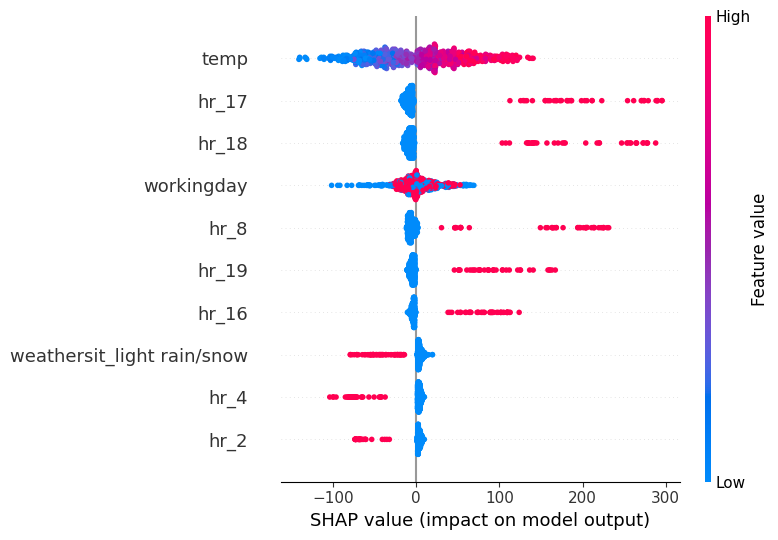

In [15]:
import shap
import numpy as np

explainer_rf = shap.TreeExplainer(rf)

shap_values_rf = explainer_rf.shap_values(X_test)

shap.summary_plot(
    shap_values_rf,
    X_test,
    max_display=10
)

  0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_474/810568038.py:21: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


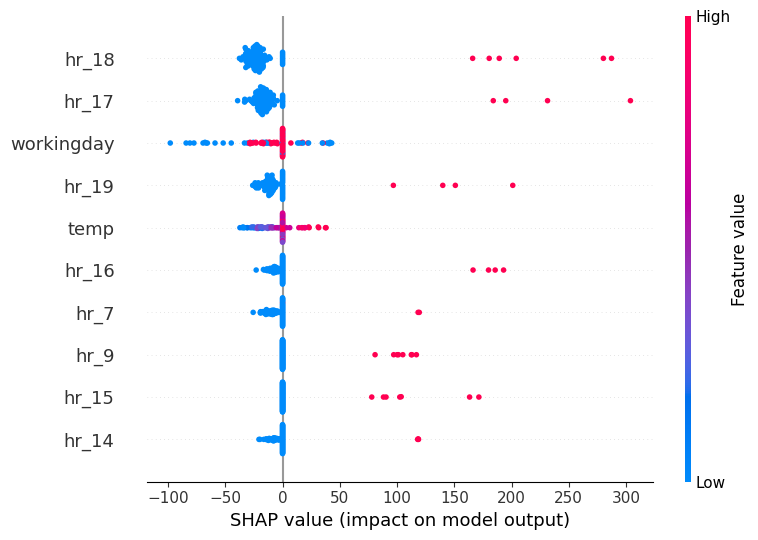

In [16]:
# DNN SHAP
background = X_train.sample(n=50, random_state=42)
X_shap = X_test.sample(n=100, random_state=42)

def predict_dnn(X):
    return dnn.predict(
        np.asarray(X, dtype="float32"),
        verbose=0
    ).ravel()

explainer_dnn = shap.KernelExplainer(
    predict_dnn,
    background
)

shap_values_dnn = explainer_dnn.shap_values(
    X_shap,
    nsamples=100
)

shap.summary_plot(
    shap_values_dnn,
    X_shap,
    max_display=10
)

  0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_474/2954078731.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


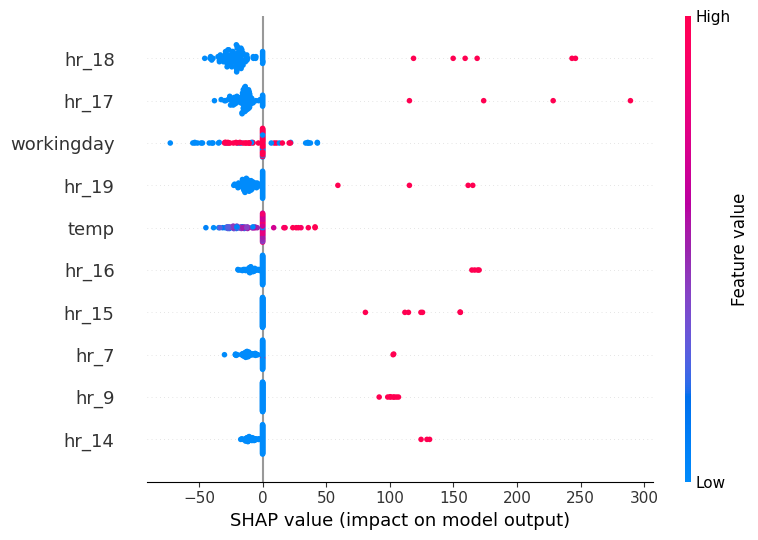

In [17]:
# CNN SHAP
def predict_cnn(X):
    X = np.asarray(X, dtype="float32").reshape(-1, 39, 1)
    return cnn.predict(X, verbose=0).ravel()

explainer_cnn = shap.KernelExplainer(
    predict_cnn,
    background
)

shap_values_cnn = explainer_cnn.shap_values(
    X_shap,
    nsamples=100
)

shap.summary_plot(
    shap_values_cnn,
    X_shap,
    max_display=10
)

DNN, 1D-CNN, Random Forest 모델의 변수 중요도를 PFI와 SHAP을 이용하여 비교하였다.
PFI 분석 결과 DNN과 1D-CNN에서는 `hr_18`, `hr_17`, `hr_8`, `workingday`, `hr_16`이 동일한 순서로 상위 5개 변수에 포함되었으나 Random Forest에서는 `temp`가 가장 중요한 변수로 나타났으며 `hr_18`, `hr_17`, `hr_8`, `workingday`가 그다음으로 중요하게 나타났다.
SHAP 분석에서도 DNN과 1D-CNN은 오후 5시에서 6시에 해당하는 시간대 변수와 근무일 여부가 중요한 것으로 나타났다. 특히 이 시간에 해당하는 경우 자전거 이용자 수 예측값을 증가시켰다. Random Forest에서는 기온이 가장 중요한 변수였으며 기온이 높을수록 예측 이용자 수가 증가하는 경향이 나타났다.
전반적으로 PFI와 SHAP은 각 모델에서 유사한 주요 변수를 제시하였다. 다만 DNN과 1D-CNN은 시간대의 중요성이 상대적으로 높았고 Random Forest는 기온의 중요성이 가장 높게 나타났다는 차이가 있었다.